In [2]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import joblib

# 1. Load cleaned data
data_path = "../data/processed/cleaned_ddos_flows.parquet"
df = pd.read_parquet(data_path)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} features")

# 2. Check exact unique labels
print("\nUnique labels in dataset:", df['Label'].unique())

# Clean and standardize target label
cleaned_labels = df['Label'].astype(str).str.strip().str.upper()

# Robust binary encoding: 0 for benign/normal, 1 for attack
y = cleaned_labels.apply(lambda label: 0 if 'BENIGN' in label else 1)
X = df.drop(columns=['Label'])

print("\n--- Verified Label Distribution ---")
print(y.value_counts())

# 3. Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\nTraining set size: {X_train.shape[0]:,}")
print(f"Testing set size: {X_test.shape[0]:,}")

# 4. Train Baseline Random Forest Classifier
print("\nTraining Baseline Random Forest model...")
rf_baseline = RandomForestClassifier(
    n_estimators=100, 
    max_depth=15, 
    random_state=42, 
    n_jobs=-1
)
rf_baseline.fit(X_train, y_train)

# 5. Evaluate on Test Set
y_pred = rf_baseline.predict(X_test)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['BENIGN (0)', 'DDoS (1)'], digits=4))

# Handle probability output safely
proba = rf_baseline.predict_proba(X_test)
if proba.shape[1] > 1:
    y_pred_proba = proba[:, 1]
    print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
else:
    print("Warning: Only single class predicted in probability output.")

# 6. Save baseline model to models/
os.makedirs("../models", exist_ok=True)
model_path = "../models/baseline_rf.joblib"
joblib.dump(rf_baseline, model_path)
print(f"\nTrained baseline model saved to: {model_path}")

Loaded dataset: 221,262 rows, 68 features

Unique labels in dataset: ['Benign', 'DDoS']
Categories (2, str): ['Benign', 'DDoS']

--- Verified Label Distribution ---
Label
1    128014
0     93248
Name: count, dtype: int64

Training set size: 177,009
Testing set size: 44,253

Training Baseline Random Forest model...

--- Classification Report ---
              precision    recall  f1-score   support

  BENIGN (0)     0.9994    0.9999    0.9997     18650
    DDoS (1)     1.0000    0.9996    0.9998     25603

    accuracy                         0.9997     44253
   macro avg     0.9997    0.9998    0.9997     44253
weighted avg     0.9997    0.9997    0.9997     44253

ROC-AUC Score: 1.0000

Trained baseline model saved to: ../models/baseline_rf.joblib


--- Top 10 Driving Features ---
                 Feature  Importance
   Fwd Packet Length Max    0.109782
    Avg Fwd Segment Size    0.094805
  Fwd Packet Length Mean    0.090416
    Fwd Act Data Packets    0.068272
       Subflow Fwd Bytes    0.065271
      Init Fwd Win Bytes    0.053863
Fwd Packets Length Total    0.052324
     Subflow Fwd Packets    0.041709
           Fwd IAT Total    0.035546
       Fwd Header Length    0.034973


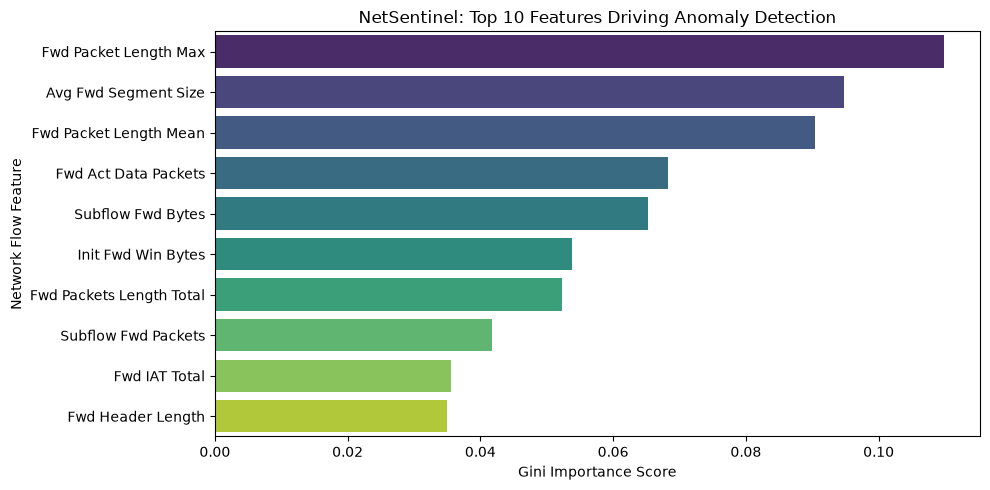

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances from trained Random Forest
importances = rf_baseline.feature_importances_
feature_names = X.columns

# Build a dataframe for top 10 features
feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

print("--- Top 10 Driving Features ---")
print(feat_df.to_string(index=False))

# Plot feature importances
plt.figure(figsize=(10, 5))
sns.barplot(data=feat_df, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title("NetSentinel: Top 10 Features Driving Anomaly Detection")
plt.xlabel("Gini Importance Score")
plt.ylabel("Network Flow Feature")
plt.tight_layout()
plt.show()

d:\nielit project\netsentinel\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


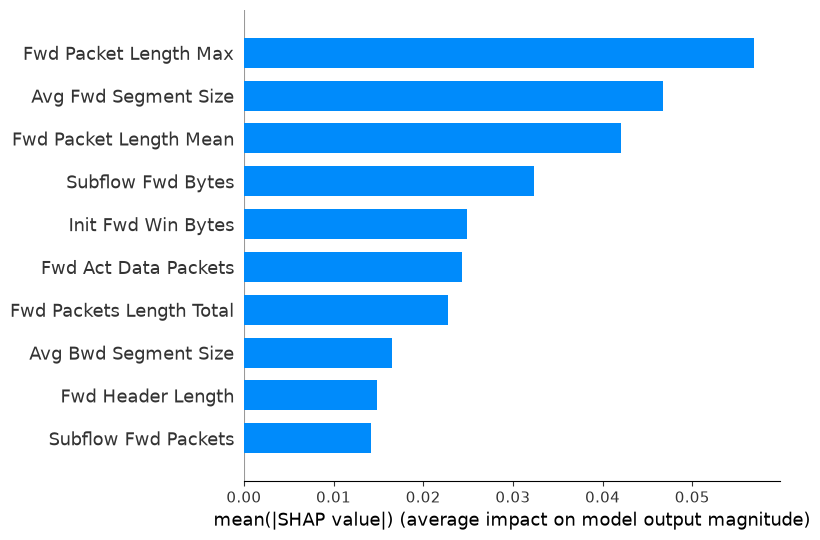

In [4]:
import shap

# Initialize SHAP TreeExplainer on the baseline model
explainer = shap.TreeExplainer(rf_baseline)

# Sample 100 instances from the test set for efficient computation
sample_X = X_test.sample(100, random_state=42)
shap_values = explainer.shap_values(sample_X)

# Handle 2-class vs 3D SHAP output dimensions safely
if isinstance(shap_values, list):
    # Class 1 (Attack) SHAP values
    shap_to_plot = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_to_plot = shap_values[:, :, 1]
else:
    shap_to_plot = shap_values

# Generate bar summary plot for top 10 contributing features
shap.summary_plot(shap_to_plot, sample_X, plot_type="bar", max_display=10)